# 🍚 Part 2: Applying KNN to a Real-World Dataset — Rice (Cammeo and Osmancik)

For this part we move beyond Iris and apply K-Nearest Neighbors to the **Rice (Cammeo and Osmancik)** dataset from the [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/545/rice+cammeo+and+osmancik).

- **Data source category:** API — we fetch the data with UCI's official Python client, `ucimlrepo`, instead of downloading a file by hand.
- **What it contains:** 3,810 images of rice grains from two certified Turkish varieties, **Cammeo** and **Osmancik**. Seven shape measurements were extracted from each grain's image.
- **Prediction task:** binary classification — given a grain's shape, predict which variety it is.

**Why this dataset suits KNN:** every feature is a numeric measurement of the grain's shape, so the "distance" between two grains has a clear meaning: grains with similar shapes are close together. KNN classifies a new grain by looking at the varieties of the grains most similar to it.

## Step 1: Acquire the Data

`fetch_ucirepo(id=545)` downloads the dataset through the UCI API and returns it as pandas DataFrames:

- `X` — the 7 input features (one row per grain).
- `y` — the target column, `Class`.

The full metadata dictionary is long, so we print only the fields we need: the dataset name, its size, whether it has missing values, and a short description. The `variables` table at the end describes each column.

In [1]:
import plotly.io as pio
pio.renderers.default = "vscode+png"  # interactive in VS Code, static PNG fallback for GitHub

from ucimlrepo import fetch_ucirepo

# fetch dataset
rice_cammeo_and_osmancik = fetch_ucirepo(id=545)

# data (as pandas dataframes)
X = rice_cammeo_and_osmancik.data.features
y = rice_cammeo_and_osmancik.data.targets

# metadata: print only the useful fields instead of the whole dict
metadata = rice_cammeo_and_osmancik.metadata
print("Name:", metadata.name)
print("Instances:", metadata.num_instances, "| Features:", metadata.num_features)
print("Missing values:", metadata.has_missing_values)
print("Abstract:", metadata.abstract)

# variable information
rice_cammeo_and_osmancik.variables


Name: Rice (Cammeo and Osmancik)
Instances: 3810 | Features: 7
Missing values: no
Abstract: A total of 3810 rice grain's images were taken for the two species, processed and feature inferences were made. 7 morphological features were obtained for each grain of rice.


,name,role,type,demographic,description,units,missing_values
0,Area,Feature,Integer,None,Returns the number of pixels within the bounda...,px,no
1,Perimeter,Feature,Continuous,None,Calculates the circumference by calculating th...,px,no
2,Major_Axis_Length,Feature,Continuous,None,The longest line that can be drawn on the rice...,NaN,no
3,Minor_Axis_Length,Feature,Continuous,None,The shortest line that can be drawn on the ric...,NaN,no
4,Eccentricity,Feature,Continuous,None,"It measures how round the ellipse, which has t...",NaN,no
5,Convex_Area,Feature,Integer,None,Returns the pixel count of the smallest convex...,NaN,no
6,Extent,Feature,Continuous,None,Returns the ratio of the region formed by the ...,NaN,no
7,Class,Target,Binary,None,Cammeo and Osmancik,NaN,no


**What we learned:**

- The dataset has **3,810 grains** and **7 features**, and UCI reports **no missing values**.
- All seven features describe the grain's shape:

| Feature | Meaning |
|---|---|
| `Area` | Number of pixels inside the grain's outline |
| `Perimeter` | Length of the grain's outline |
| `Major_Axis_Length` | Longest line that can be drawn across the grain (its length) |
| `Minor_Axis_Length` | Shortest line across the grain (its width) |
| `Eccentricity` | How elongated the grain is (0 = a perfect circle, closer to 1 = longer and thinner) |
| `Convex_Area` | Pixel count of the smallest convex shape that encloses the grain |
| `Extent` | Ratio of the grain's area to the area of its bounding box |

- The target, `Class`, is **binary**: Cammeo or Osmancik.

### Step 1b: Explore the Data

Before preprocessing, we check three things:

1. **Shapes:** do `X` and `y` have the same number of rows?
2. **Class balance:** is one variety much more common than the other? This tells us whether accuracy alone is a fair metric.
3. **Feature scales:** what range does each feature cover? KNN measures distances, so features with large values could dominate.

In [2]:
print("Features shape:", X.shape)
print("Target shape:", y.shape)

# Class balance: counts and proportions
print(y["Class"].value_counts())
print(y["Class"].value_counts(normalize=True).round(3))

# Feature scales: compare Area with Eccentricity
X.describe().T[["mean", "std", "min", "max"]]


Features shape: (3810, 7)
Target shape: (3810, 1)
Class
Osmancik    2180
Cammeo      1630
Name: count, dtype: int64
Class
Osmancik    0.572
Cammeo      0.428
Name: proportion, dtype: float64


,mean,std,min,max
Area,12667.727559,1732.367706,7551.000000,18913.000000
Perimeter,454.239180,35.597081,359.100006,548.445984
Major_Axis_Length,188.776222,17.448679,145.264465,239.010498
Minor_Axis_Length,86.313750,5.729817,59.532406,107.542450
Eccentricity,0.886871,0.020818,0.777233,0.948007
Convex_Area,12952.496850,1776.972042,7723.000000,19099.000000
Extent,0.661934,0.077239,0.497413,0.861050


**Observations:**

- `X` has 3,810 rows and 7 columns, and `y` has 3,810 labels, so they line up.
- **Class balance:** about **57% Osmancik** (2,180) and **43% Cammeo** (1,630). The data is slightly imbalanced but not severely, so accuracy is meaningful. We will still report precision and recall to check that both varieties are predicted well.
- **Feature scales differ hugely:** `Area` and `Convex_Area` are in the **thousands** (≈7,500–19,000), while `Eccentricity` and `Extent` are **below 1**. With raw values, a difference of a few pixels in `Area` would outweigh any difference in `Eccentricity` when KNN computes distances. This is why we must **scale the features** in Step 2.

#### Visualizing the Two Varieties

As we did with Iris, we plot two features to see how the classes cluster. We chose **Major Axis Length** (how long a grain is) and **Eccentricity** (how elongated it is) because they separate the two varieties well.

The chart is made with **Plotly**, so it is interactive: hover over a point to see that grain's measurements, click a variety in the legend to hide or show it, and drag to zoom. The **violin plots** along the top and right edges show how each variety is distributed along that axis.

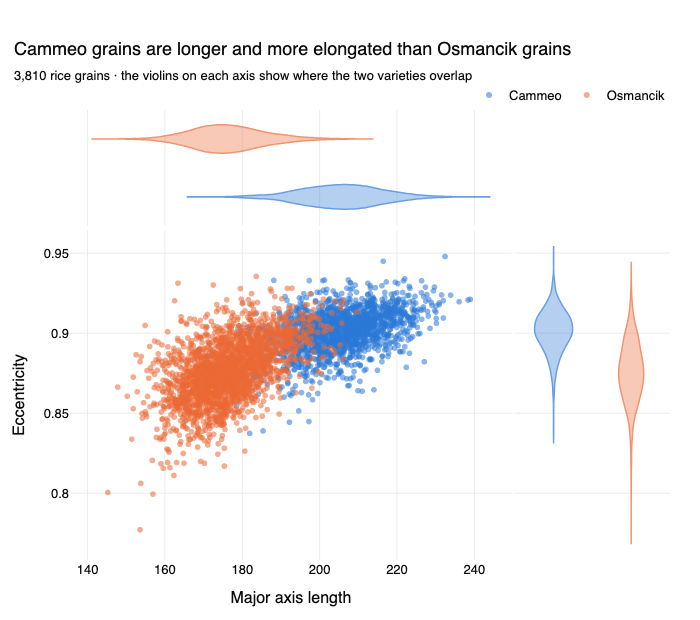

In [3]:
import plotly.express as px

# Combine features and labels into one DataFrame so Plotly can colour by class
rice_df = X.assign(Class=y["Class"])

# Two colours that stay distinguishable for colour-blind readers
class_colors = {"Cammeo": "#2a78d6", "Osmancik": "#eb6834"}

fig = px.scatter(
    rice_df,
    x="Major_Axis_Length",
    y="Eccentricity",
    color="Class",
    color_discrete_map=class_colors,
    category_orders={"Class": ["Cammeo", "Osmancik"]},
    marginal_x="violin",  # distribution of each class along the x-axis
    marginal_y="violin",  # distribution of each class along the y-axis
    opacity=0.55,
    hover_data={
        "Major_Axis_Length": ":.1f",
        "Eccentricity": ":.3f",
        "Minor_Axis_Length": ":.1f",
        "Area": ":,",
        "Perimeter": ":.1f",
    },
    labels={
        "Major_Axis_Length": "Major axis length",
        "Minor_Axis_Length": "Minor axis length",
        "Class": "Variety",
    },
    template="plotly_white",
    height=620,
)

# Thin white outline separates overlapping points
fig.update_traces(marker=dict(size=8, line=dict(width=0.6, color="white")), selector=dict(type="scatter"))
fig.update_traces(opacity=0.7, line_width=1.5, points=False, selector=dict(type="violin"))

fig.update_layout(
    title=dict(
        text="Cammeo grains are longer and more elongated than Osmancik grains",
        subtitle=dict(text="3,810 rice grains · the violins on each axis show where the two varieties overlap"),
        x=0.02,
    ),
    legend=dict(title=None, orientation="h", yanchor="bottom", y=1.0, xanchor="right", x=1),
    font=dict(family="Inter, Helvetica, Arial, sans-serif", size=13, color="#0b0b0b"),
    hoverlabel=dict(bgcolor="white", font_size=12),
    margin=dict(l=70, r=30, t=110, b=60),
)
fig.update_xaxes(gridcolor="#ececea", zeroline=False)
fig.update_yaxes(gridcolor="#ececea", zeroline=False)

fig.show()

**What the plot shows:**

- **Cammeo grains are longer and more elongated:** they sit to the right (major axis ≈ 190–240) and higher up (eccentricity ≈ 0.88–0.93).
- **Osmancik grains are shorter and rounder:** they sit to the left (major axis ≈ 145–200) and lower down.
- **The varieties overlap** in the middle (major axis ≈ 185–200), and the violins on both axes overlap too. A grain in this region has neighbors from both varieties, so this is where we expect KNN to make most of its mistakes.
- This is only two of the seven features. KNN will use all seven, which should separate the classes better than this 2D view suggests.

## Step 2: Preprocess the Data

To prepare the data for KNN, we:

1. **Check for missing values and duplicates**, which would distort the distance calculations.
2. **Encode the target**, turning the text labels `Cammeo` and `Osmancik` into the integers 0 and 1.
3. **Split the data** into a training set (80%) and a test set (20%). We use `stratify` so both sets keep the same 57/43 class balance as the full dataset, and `random_state=42` so the split is the same every time the notebook runs.

In [4]:
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

# 1. Check for missing values and duplicates
print("Missing values per column:")
print(X.isna().sum())
print("Duplicate rows:", X.duplicated().sum())

# 2. Encode the target as integers (y is a DataFrame, so pass the column)
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y["Class"])
print("Class encoding:", dict(zip(label_encoder.classes_, range(len(label_encoder.classes_)))))

# 3. Stratified split keeps the same class balance in train and test
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, stratify=y_encoded, random_state=42
)
print("Train size:", X_train.shape[0], "| Test size:", X_test.shape[0])


Missing values per column:
Area                 0
Perimeter            0
Major_Axis_Length    0
Minor_Axis_Length    0
Eccentricity         0
Convex_Area          0
Extent               0
dtype: int64
Duplicate rows: 0
Class encoding: {'Cammeo': 0, 'Osmancik': 1}
Train size: 3048 | Test size: 762


**Results:**

- **No missing values and no duplicate rows**, so no cleaning is needed.
- **No categorical features to encode:** all seven features are already numeric. Only the target needed encoding.
- **Encoding:** `Cammeo → 0`, `Osmancik → 1`. `LabelEncoder` assigns numbers in alphabetical order. This matters later: precision and recall scores for a binary target are reported for the class encoded as `1` (Osmancik).
- **Split:** **3,048** grains for training and **762** for testing.

### Normalizing the Features

As we saw in Step 1b, the features are on very different scales. `StandardScaler` rescales each feature to have a **mean of 0** and a **standard deviation of 1**, so every feature contributes equally to the distance.

⚠️ **The scaler is fitted on the training set only.** `fit_transform` learns each feature's mean and standard deviation from the training data, and `transform` then applies those same values to the test set. If we fitted on the full dataset, information about the test set would *leak* into training, and our test score would look better than the model really is.

In [5]:
import pandas as pd

# 4. Scale features: fit on the training set only, then apply the same scaling to test
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Check: every training feature should now have mean ~0 and std ~1
pd.DataFrame(X_train_scaled, columns=X.columns).describe().T[["mean", "std"]].round(2)


,mean,std
Area,0.0,1.0
Perimeter,-0.0,1.0
Major_Axis_Length,-0.0,1.0
Minor_Axis_Length,-0.0,1.0
Eccentricity,-0.0,1.0
Convex_Area,0.0,1.0
Extent,0.0,1.0


**Check:** every feature in the scaled training set now has a mean of **0** and a standard deviation of **1** (a `-0.0` in the table is just a tiny rounding error). All seven features are now on the same scale.

The data is ready for **Step 3: training and evaluating KNN**, which uses `X_train_scaled`, `X_test_scaled`, `y_train`, and `y_test`.

## Step 3: Train and Evaluate KNN

We train a KNN classifier with `k = 5` on the **scaled** training data and predict the variety of every grain in the **scaled** test set.

In [6]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)
y_pred = knn.predict(X_test_scaled)


**Why "training" is instant:** KNN is a *lazy learner*. Calling `fit` does not learn any weights or rules; it simply stores the 3,048 training grains. All the real work happens at prediction time, when KNN measures the distance from each test grain to every stored grain and takes a majority vote among the 5 closest.

### Evaluating the Model

Accuracy alone can hide problems, so we also report **precision** (of the grains predicted as a class, how many really are that class), **recall** (of the grains that really are a class, how many we found), and **F1-score** (the balance of the two).

In [7]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

# Always (y_true, y_pred) in that order
print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall   :", round(recall_score(y_test, y_pred), 4))
print("F1-score :", round(f1_score(y_test, y_pred), 4))
print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))

Accuracy : 0.9094
Precision: 0.9124
Recall   : 0.9312
F1-score : 0.9217

Classification report:
              precision    recall  f1-score   support

      Cammeo       0.91      0.88      0.89       326
    Osmancik       0.91      0.93      0.92       436

    accuracy                           0.91       762
   macro avg       0.91      0.91      0.91       762
weighted avg       0.91      0.91      0.91       762



**Results:**

- **Accuracy is 90.9%:** 693 of the 762 test grains are classified correctly.
- The standalone precision, recall, and F1 scores describe **Osmancik only**, because `LabelEncoder` encoded Osmancik as `1` and scikit-learn reports binary metrics for the positive class (`1`) by default. The classification report shows both classes.
- **Cammeo has the lower recall (0.88 vs 0.93):** the model misses about 12% of real Cammeo grains, labelling them Osmancik. Osmancik is the larger class (436 vs 326 test grains), so in the ambiguous overlap region a grain's nearest neighbors are more likely to be Osmancik.
- Precision is the same for both varieties (0.91), so when the model does predict a variety, it is right about 91% of the time either way.

### Confusion Matrix

The confusion matrix breaks the predictions down further: rows are the true variety, columns are the predicted variety, and the diagonal holds the correct predictions.

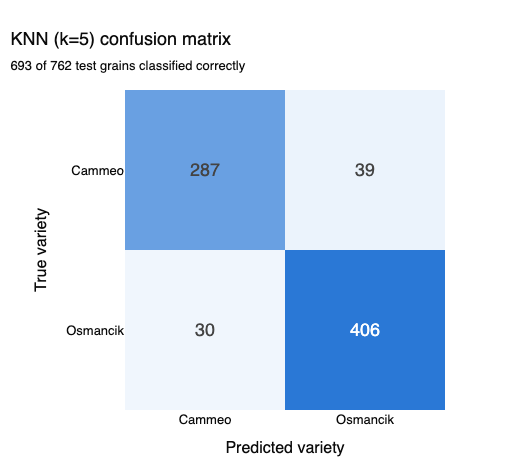

In [8]:
import plotly.express as px
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)
class_names = list(label_encoder.classes_)

fig = px.imshow(
    cm,
    x=class_names,
    y=class_names,
    text_auto=True,  # print the count in each cell
    color_continuous_scale=["#f0f6fd", "#2a78d6"],  # light to dark blue: more grains = darker
    labels={"x": "Predicted variety", "y": "True variety", "color": "Grains"},
    template="plotly_white",
    width=520,
    height=470,
)
fig.update_traces(textfont_size=18, hovertemplate="True: %{y}<br>Predicted: %{x}<br>Grains: %{z}<extra></extra>")
fig.update_layout(
    title=dict(
        text="KNN (k=5) confusion matrix",
        subtitle=dict(text=f"{cm.trace()} of {cm.sum()} test grains classified correctly"),
        x=0.02,
    ),
    font=dict(family="Inter, Helvetica, Arial, sans-serif", size=13, color="#0b0b0b"),
    coloraxis_showscale=False,  # the numbers are printed in the cells, so no colour bar needed
    margin=dict(l=80, r=30, t=90, b=60),
)
fig.update_xaxes(side="bottom")
fig.show()


**What the confusion matrix shows:**

- **287** Cammeo and **406** Osmancik grains are classified correctly.
- The most common mistake is **Cammeo predicted as Osmancik (39 grains)**, compared with **30** Osmancik grains predicted as Cammeo. This matches the lower Cammeo recall.
- These errors come from the **overlap region** in our scatter plot: short Cammeo grains and long Osmancik grains have very similar shapes, so their nearest neighbors are a mix of both varieties.

### Experiment: Does Scaling Really Matter?

In Step 1b we argued that unscaled features would distort the distances. To test it, we train the same `k = 5` model on the **raw** features and compare.

In [9]:
# Same model, same split, but trained and tested on the raw (unscaled) features
knn_unscaled = KNeighborsClassifier(n_neighbors=5)
knn_unscaled.fit(X_train, y_train)
y_pred_unscaled = knn_unscaled.predict(X_test)

acc_unscaled = accuracy_score(y_test, y_pred_unscaled)
acc_scaled = accuracy_score(y_test, y_pred)
print(f"Accuracy without scaling: {acc_unscaled:.4f}")
print(f"Accuracy with scaling:    {acc_scaled:.4f}")
print(f"Improvement:              {acc_scaled - acc_unscaled:+.4f}")


Accuracy without scaling: 0.8648
Accuracy with scaling:    0.9094
Improvement:              +0.0446


**Scaling improves accuracy by 4.5 percentage points (86.5% → 90.9%).**

Without scaling, `Area` and `Convex_Area` (values in the thousands, standard deviation ≈ 1,700) dominate the distance calculation, while `Eccentricity` (standard deviation ≈ 0.02) and `Extent` contribute almost nothing. KNN effectively ignores the shape features that describe how elongated a grain is, and those are some of the most useful for telling the varieties apart. This confirms that scaling is essential for distance-based algorithms like KNN.

# 🏗️ Part 3: Architecting with the ML Pipeline Pattern

In Part 2 we wrote the experiment as a sequence of separate cells. That works once, but it is hard to rerun with different settings, hard to test, and easy to break by running cells out of order.

The **ML Pipeline Pattern** fixes this by turning each stage into a small, reusable function and chaining them together:

**Load → Clean → Split → Preprocess → Train → Evaluate**

Each function does one job, takes its inputs as arguments, and returns its outputs, so the whole experiment can be rerun with a single call.

In [10]:
# ML Pipeline Pattern: each stage is a small, reusable function
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score


def load_data(uci_id=545, target_col="Class"):
    """Stage 1 - Data Acquisition: fetch the dataset from the UCI ML Repository API."""
    dataset = fetch_ucirepo(id=uci_id)
    X = dataset.data.features
    y = dataset.data.targets[target_col]
    return X, y


def clean_data(X, y):
    """Stage 2a - Data Cleaning: drop rows with missing values and duplicate rows."""
    # Join X and y so the same rows are dropped from both
    data = X.assign(_target=y.values).dropna().drop_duplicates()
    return data.drop(columns="_target"), data["_target"]


def split_data(X, y, test_size=0.2, random_state=42):
    """Stage 2b - Encode the target and make a stratified train/test split."""
    encoder = LabelEncoder()
    y_encoded = encoder.fit_transform(y)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y_encoded, test_size=test_size, stratify=y_encoded, random_state=random_state
    )
    return X_train, X_test, y_train, y_test, encoder


def preprocess_data(X_train, X_test):
    """Stage 3 - Preprocessing: scale features, fitting the scaler on training data only."""
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    return X_train_scaled, X_test_scaled, scaler


def train_model(X_train, y_train, k=5):
    """Stage 4 - Model Training: fit a KNN classifier."""
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    return model


def evaluate_model(model, X_test, y_test):
    """Stage 5 - Evaluation: return a dictionary of classification metrics."""
    y_pred = model.predict(X_test)
    return {
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred),
        "recall": recall_score(y_test, y_pred),
        "f1": f1_score(y_test, y_pred),
    }


def run_pipeline(k=5, data=None):
    """Chain every stage in order. Pass `data=(X, y)` to skip calling the API again."""
    X, y = data if data is not None else load_data()
    X, y = clean_data(X, y)
    X_train, X_test, y_train, y_test, encoder = split_data(X, y)
    X_train_scaled, X_test_scaled, scaler = preprocess_data(X_train, X_test)
    model = train_model(X_train_scaled, y_train, k=k)
    metrics = evaluate_model(model, X_test_scaled, y_test)
    return model, metrics


**Design decisions:**

- **`preprocess_data` takes both `X_train` and `X_test`.** The instructor's scaffold had `preprocess_data(X)` with a single argument, but the scaler must be **fitted on the training set only** and then applied to the test set. A one-argument function would either fit on all the data (leaking test information) or scale the two sets differently. Passing both lets the function fit once on train and transform both consistently.
- **`clean_data` joins `X` and `y` before dropping rows,** so a row removed from the features is also removed from the labels and the two stay aligned.
- **`evaluate_model` returns a dictionary instead of printing,** so results from different runs can be collected and compared.
- **`run_pipeline` accepts optional `data`,** so we can load from the API once and reuse it rather than calling the API on every run.

In [11]:
# Run the whole pipeline end to end with one call
model, metrics = run_pipeline(k=5)

print("Pipeline results (k=5):")
for name, value in metrics.items():
    print(f"  {name:<9}: {value:.4f}")


Pipeline results (k=5):
  accuracy : 0.9094
  precision: 0.9124
  recall   : 0.9312
  f1       : 0.9217


The pipeline reproduces the Part 2 results exactly (accuracy **0.9094**), which confirms the refactor did not change the experiment's behavior.

### Reusing the Pipeline: Comparing Values of k

Because every stage is a function, comparing different values of *k* takes a single loop.

In [12]:
import pandas as pd

# Load the data once, then reuse the pipeline for several values of k
rice_data = load_data()
k_values = [1, 3, 5, 7, 11, 15, 25]

k_results = pd.DataFrame(
    [{"k": k, **run_pipeline(k=k, data=rice_data)[1]} for k in k_values]
).set_index("k")
k_results.round(4)


,accuracy,precision,recall,f1
k,,,,
1,0.8714,0.8772,0.9014,0.8891
3,0.8976,0.8978,0.9266,0.9120
5,0.9094,0.9124,0.9312,0.9217
7,0.9186,0.9156,0.9450,0.9300
11,0.9121,0.9165,0.9312,0.9238
15,0.9121,0.9109,0.9381,0.9243
25,0.9094,0.9087,0.9358,0.9220


**Observations:**

- **k = 1 is the worst (87.1%).** Each prediction depends on a single neighbor, so one unusual or mislabelled training grain is enough to cause a mistake. The model *overfits* to noise.
- **Accuracy rises up to k = 7 (91.9%), then levels off around 91%.** Averaging over more neighbors smooths out noise, but grains in the overlap region are genuinely ambiguous: no matter how many neighbors we ask, some short Cammeo grains look exactly like Osmancik grains. That limits how far *k* alone can improve the model.
- We use **odd values of *k*** so a vote between two classes can never tie.

### Bonus: Hyperparameter Tuning with scikit-learn's `Pipeline`

scikit-learn provides the Pipeline Pattern as a built-in class. A `Pipeline` chains the scaler and the classifier into a **single estimator**, which makes it safe to combine with cross-validation.

We use `GridSearchCV` to try every combination of:

- **`n_neighbors`:** odd values from 1 to 31.
- **`weights`:** `uniform` (every neighbor gets an equal vote) or `distance` (closer neighbors get a bigger vote).
- **`metric`:** `euclidean` (straight-line distance) or `manhattan` (sum of the differences along each feature).

Each combination is scored with **5-fold cross-validation on the training set only**. The test set is used once, at the very end.

In [13]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Reuse our own stages to get an unscaled train/test split
X_clean, y_clean = clean_data(*rice_data)
X_train, X_test, y_train, y_test, encoder = split_data(X_clean, y_clean)

# scikit-learn's Pipeline chains the scaler and the model into one estimator
knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier()),
])

# Parameter names are "<step name>__<parameter>"
param_grid = {
    "knn__n_neighbors": list(range(1, 32, 2)),
    "knn__weights": ["uniform", "distance"],
    "knn__metric": ["euclidean", "manhattan"],
}

search = GridSearchCV(
    knn_pipeline,
    param_grid,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring="accuracy",
    n_jobs=-1,
)
search.fit(X_train, y_train)  # unscaled data: the pipeline scales inside each fold

print("Best parameters:", search.best_params_)
print(f"Best cross-validation accuracy: {search.best_score_:.4f}")
print(f"Test accuracy of the tuned model: {search.score(X_test, y_test):.4f}")


Best parameters: {'knn__metric': 'euclidean', 'knn__n_neighbors': 25, 'knn__weights': 'uniform'}
Best cross-validation accuracy: 0.9308
Test accuracy of the tuned model: 0.9094


**Why we pass unscaled data to the pipeline:** in cross-validation, each fold takes a turn as the validation set. If we scaled all the training data first, the scaler would have already seen the validation fold's values, a form of **data leakage** that makes the cross-validation score look better than it really is. Inside a `Pipeline`, the scaler is re-fitted on the training folds only, every time.

**What "best k = 25" means:**

- To classify a new grain, the model finds the **25 most similar grains** in the training data and predicts the variety held by the majority (at least 13 of the 25).
- That is still a small, local neighborhood: 25 grains out of about 2,400 in each training fold (≈1%).
- A larger *k* gives a **smoother decision boundary**: individual unusual grains have less influence, at the cost of slower predictions and, if *k* grows too large, blurring real differences between the varieties.

**Did tuning actually help?** Not meaningfully. k = 25 has the highest cross-validation accuracy (**93.08%**), but k = 7 scores 92.81%, a difference of 0.27 percentage points, while the fold-to-fold standard deviation is about **0.9 percentage points**. On the test set, the tuned model scores **90.94%**, exactly the same as our simple `k = 5` model. Any *k* from about 5 to 31 performs equally well within the noise, so a smaller *k* such as 5 or 7 is a perfectly good (and faster) choice.

#### Accuracy vs. k

The chart shows the mean cross-validation accuracy for each *k* (uniform weights, Euclidean distance), with error bars showing how much the accuracy varies between folds.

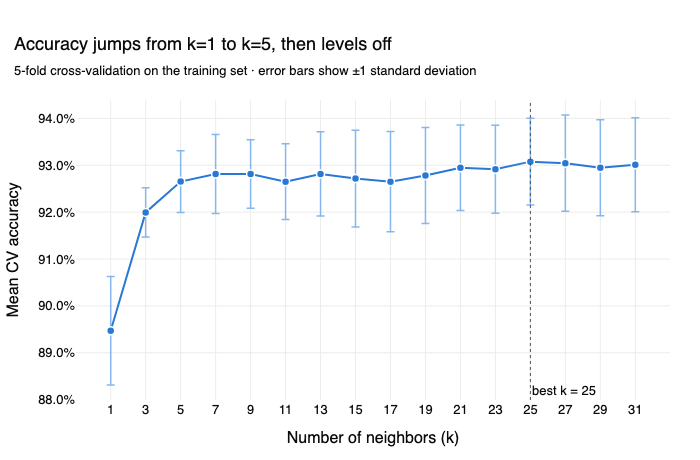

In [14]:
import plotly.express as px

# One row per parameter combination; keep uniform weights + euclidean distance
cv_results = pd.DataFrame(search.cv_results_)
curve = cv_results[
    (cv_results["param_knn__weights"] == "uniform")
    & (cv_results["param_knn__metric"] == "euclidean")
].sort_values("param_knn__n_neighbors")

best_k = search.best_params_["knn__n_neighbors"]

fig = px.line(
    curve,
    x="param_knn__n_neighbors",
    y="mean_test_score",
    error_y="std_test_score",
    markers=True,
    labels={"param_knn__n_neighbors": "Number of neighbors (k)", "mean_test_score": "Mean CV accuracy"},
    template="plotly_white",
    height=460,
)
fig.update_traces(
    line=dict(color="#2a78d6", width=2),
    marker=dict(size=8, line=dict(width=1.5, color="white")),
    error_y=dict(color="#86b6ef", thickness=1.5, width=4),
    hovertemplate="k = %{x}<br>CV accuracy = %{y:.4f}<extra></extra>",
)
fig.add_vline(x=best_k, line=dict(color="#52514e", width=1, dash="dot"),
              annotation_text=f"best k = {best_k}", annotation_position="bottom right")
fig.update_layout(
    title=dict(
        text="Accuracy jumps from k=1 to k=5, then levels off",
        subtitle=dict(text="5-fold cross-validation on the training set · error bars show ±1 standard deviation"),
        x=0.02,
    ),
    font=dict(family="Inter, Helvetica, Arial, sans-serif", size=13, color="#0b0b0b"),
    margin=dict(l=70, r=30, t=100, b=60),
)
fig.update_xaxes(tickvals=param_grid["knn__n_neighbors"], gridcolor="#ececea", zeroline=False)  # tick every k we tested
fig.update_yaxes(tickformat=".1%", gridcolor="#ececea", zeroline=False)
fig.show()


The curve jumps from k = 1 to k = 5 and then stays almost flat. Beyond k = 5, the error bars of every *k* overlap heavily, which is why the "best" *k* is not meaningfully better than its neighbors.

# 🔍 Reflection

In this section we reflect on the five discussion questions from the workshop, using the results from Parts 2 and 3.

### 1. How did KNN perform on our dataset?

KNN performed well. With `k = 5` and scaled features, it reached **90.9% accuracy on the test set**, classifying 693 of 762 grains correctly, and about **92.7% in 5-fold cross-validation**. Precision was the same for both varieties (0.91), so when the model predicts a variety it is usually right.

The errors were not evenly spread. **Cammeo had a lower recall (0.88) than Osmancik (0.93)**: the most common mistake was a Cammeo grain labelled as Osmancik (39 grains, against 30 the other way). Our scatter plot explains why. The two varieties overlap where short Cammeo grains and long Osmancik grains have nearly identical shapes, and because Osmancik is the larger class, the nearest neighbors in that region tend to be Osmancik. A good part of the remaining error comes from grains that are genuinely ambiguous from their shape measurements alone, which no choice of *k* can fix.

### 2. What preprocessing decisions most affected performance?

**Feature scaling had by far the biggest effect.** Training the same `k = 5` model on the raw features dropped accuracy from 90.9% to **86.5%**, a loss of 4.5 percentage points. Without scaling, `Area` and `Convex_Area` (in the thousands) dominate the distance calculation and the shape features like `Eccentricity` are effectively ignored.

By comparison, **hyperparameter tuning changed almost nothing**: the tuned model (k = 25) scored exactly the same on the test set as plain k = 5. For KNN, getting the distances right mattered much more than choosing *k*.

Two other decisions did not raise the score but made it **trustworthy**:

- **Fitting the scaler on the training set only** (and using a `Pipeline` during cross-validation) prevents test data from leaking into training, so our accuracy is an honest estimate.
- **Stratified splitting** kept the 57/43 class balance in both the training and test sets, so the test set is representative.

Cleaning had no effect on this dataset because it has no missing values or duplicates, but keeping the step in the pipeline means it would protect us on messier data.

### 3. What are the strengths and weaknesses of KNN?

**Strengths**

- **Simple and intuitive:** "a grain is probably the same variety as the grains most similar to it" is easy to explain to anyone.
- **No training phase:** `fit` only stores the data, so adding new labelled examples is trivial.
- **Flexible decision boundaries:** KNN makes no assumption about the shape of the boundary between classes, so it can handle non-linear patterns.
- **Few hyperparameters:** mainly *k*, the distance metric, and the weighting, and our results show it is not very sensitive to *k* once *k* ≥ 5.
- **Explainable predictions:** we can show the actual neighbors that led to a prediction.

**Weaknesses**

- **Very sensitive to feature scaling**, as our 4.5-point drop showed.
- **Slow and memory-hungry at prediction time:** every prediction compares the new point against every stored training point, so cost grows with the size of the data.
- **Struggles with many features (the "curse of dimensionality"):** in high dimensions, all points end up roughly equally far apart, so "nearest" stops being meaningful.
- **Affected by class imbalance:** the larger class tends to win close votes, which we saw in the lower Cammeo recall.
- **No built-in feature importance:** KNN does not tell us which measurements matter most, and irrelevant features add noise to the distance.

### 4. When would we *not* use KNN in practice?

- **Very large datasets or real-time systems:** if predictions must be fast and the training set has millions of rows, comparing against every stored point is too slow. A model that learns a compact set of parameters (like logistic regression or a tree-based model) predicts much faster.
- **High-dimensional data**, such as raw text or image pixels, where distances lose their meaning. Here we would first reduce the dimensions or use a different model.
- **Mostly categorical or mixed data**, where there is no natural way to measure distance between values like colours or country names.
- **Severely imbalanced problems**, such as fraud detection, where the rare class would almost always be outvoted unless we rebalance the data or weight the votes.
- **When we need to explain which features drive the outcome**, for example to a domain expert. A linear model or decision tree makes those relationships visible; KNN does not.
- **Data with many irrelevant or noisy features**, unless we do feature selection first, because every feature contributes equally to the distance.

For the Rice dataset, KNN is a reasonable choice: it is small, has only seven numeric features, and the classes form clear clusters. It would be worth comparing against a simpler model such as logistic regression, which could reach similar accuracy with much faster predictions.

### 5. How could this workflow be extended in an MLOps context?

Our Part 3 pipeline is already the starting point: every stage is a function and the whole experiment runs with one call. To take it further:

- **Package the code:** move the pipeline functions out of the notebook into a Python module so they can be imported, tested, and run as a script.
- **Automated testing and CI/CD:** write unit tests for each stage (for example, that `clean_data` keeps `X` and `y` aligned, or that the scaler is only fitted on training data), and run them automatically with a CI service such as GitHub Actions on every push.
- **Version the data and the model:** record which dataset version and which parameters produced each model, and save the fitted `Pipeline` (scaler and classifier together) with `joblib` so the exact same preprocessing is used in production.
- **Experiment tracking:** log every run's parameters (*k*, metric, weighting) and metrics with a tool like MLflow, instead of comparing tables by hand.
- **Deployment:** serve the saved pipeline behind a small API that accepts a grain's seven measurements and returns the predicted variety.
- **Monitoring and retraining:** compare the feature distributions of incoming grains against the training data to detect **data drift** (for example, a new camera changing the pixel scale of `Area`), track accuracy as new labelled grains arrive, and trigger automatic retraining when performance drops.

## 🤝 Peer Comparison

We worked with **Group 3** ([ricardo-mohammed/k-nearest-neighbors](https://github.com/ricardo-mohammed/k-nearest-neighbors)), who applied KNN to the **Palmer Penguins** dataset to predict penguin species. Both teams reviewed each other's work. Our full review of their project, including the extra experiments we ran on their pipeline, is in [`Peer_Team_Review.md`](Peer_Team_Review.md).

| | Our project: Rice (Cammeo / Osmancik) | Group 3: Palmer Penguins |
|---|---|---|
| Data source | UCI ML Repository API (`fetch_ucirepo(id=545)`) | `seaborn.load_dataset('penguins')` |
| Size | 3,810 grains | 344 penguins |
| Classes | 2 | 3 (Adelie, Chinstrap, Gentoo) |
| Features | 7 numeric shape measurements | 4 numeric measurements + 2 categorical (`island`, `sex`) |
| Missing values | None | 2 per measurement, 11 in `sex` (imputed with median / most frequent) |
| Preprocessing | `StandardScaler` | Imputation, `StandardScaler`, one-hot encoding |
| Split | Stratified 80/20, seed 42 | Stratified 80/20, seed 42 |
| Test set size | 762 | 69 |
| Test accuracy (k = 5, scaled) | **90.94%** (693 / 762) | **98.55%** (68 / 69) |
| Test accuracy without scaling | 86.48% | 78.26%* |
| CV accuracy across values of k | 92.7–93.1% (k = 5 to 31) | 98.9–99.3%* (k = 1 to 15) |
| Errors | 39 Cammeo → Osmancik, 30 Osmancik → Cammeo | 1 Adelie → Chinstrap |

\* Measured by our team by re-running Group 3's pipeline; their notebook reports only the scaled k = 5 result.

### What the comparison shows

- **The accuracies are not directly comparable.** Group 3's problem has three well-separated species and only 69 test penguins, so a single error moves their accuracy by 1.45 percentage points; one error in our 762-grain test set moves it by 0.13. Their higher score reflects an easier, smaller problem, not a better use of KNN.
- **Both projects teach the same main lesson: scaling matters far more than *k*.** Removing `StandardScaler` cost us 4.5 percentage points and cost Group 3 about 20, because their `body_mass_g` (in the thousands of grams) dominated every distance. In contrast, every reasonable *k* performed within the noise in both projects.
- **Both models fail on genuinely ambiguous cases.** Our errors come from the region where short Cammeo and long Osmancik grains have the same shape; Group 3's single error is an Adelie from Dream island (where Chinstraps live) with an unusually long, Chinstrap-like bill.
- **The two projects complement each other.** Group 3's data was messier, so their preprocessing was broader: they handled missing values and categorical features with a `ColumnTransformer`, which we would adopt if our data had either. Our data was clean, so we invested in experiments instead: the scaling test, the comparison of *k*, and cross-validated grid search, which would strengthen their analysis.

### Feedback from Group 3 on our work

Group 3 compared their project with ours in their own repository. Their main observations:

- They pointed out that the two results are **"not a fair head-to-head performance ranking"**, because the number of classes, sample sizes, and feature distributions differ.
- They noted that our scaling experiment (86.48% → 90.94%) **"gives experimental support"** to their own explanation that distance-based models should not let large-scale features dominate smaller ones.
- Their comparison table lists our **additional experiments** (scaling comparison, multiple values of *k*, grid search, and 5-fold cross-validation) alongside their own confusion matrix and classification report.
- They concluded that in both projects **the confusion matrix is more informative than accuracy alone**.
- They noted that the MLOps improvements discussed for both projects (tests, saving the fitted pipeline, tracking metrics, and drift monitoring) are **future ideas, not implemented features**.

We agree with their observations. Their point about MLOps is fair: our pipeline functions are a starting point, but we have not yet packaged, tested, or deployed them.